In [437]:
import pandas as pd
import matplotlib.pyplot as plt

In [438]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [439]:
df = pd.read_csv("/content/drive/MyDrive/SEM 7/MACHINE LEARNING II/Coffe_sales.csv")

In [440]:
penjualan_harian = (
    df.groupby('Date')
    .size()
    .reset_index(name='Jumlah Penjualan')
)

penjualan_harian.head(10)

,Date,Jumlah Penjualan
0,2024-03-01,11
1,2024-03-02,6
2,2024-03-03,9
3,2024-03-04,4
4,2024-03-05,9
5,2024-03-06,4
6,2024-03-07,4
7,2024-03-08,8
8,2024-03-09,13
9,2024-03-10,3


In [441]:
print("Jumlah tanggal unik:", df['Date'].nunique())

Jumlah tanggal unik: 381


Data Time Series

In [442]:
import pandas as pd

df['Date'] = pd.to_datetime(df['Date'])

# Membuat rentang tanggal lengkap
semua_tanggal = pd.date_range(
    start=df['Date'].min(),
    end=df['Date'].max(),
    freq='D'
)

# Menghitung seluruh penjualan per tanggal
data_harian = (
    df.groupby('Date')
      .size()
      .reindex(semua_tanggal, fill_value=0)
      .rename_axis('ds')
      .reset_index(name='y')
)

display(data_harian.head(10))

,ds,y
0,2024-03-01,11
1,2024-03-02,6
2,2024-03-03,9
3,2024-03-04,4
4,2024-03-05,9
5,2024-03-06,4
6,2024-03-07,4
7,2024-03-08,8
8,2024-03-09,13
9,2024-03-10,3


Menyiapkan data untuk Prophet

In [443]:
data_prophet = penjualan_harian.rename(columns={
    'Date': 'ds',
    'Jumlah Penjualan': 'y'
})

data_prophet['ds'] = pd.to_datetime(data_prophet['ds'])
data_prophet = data_prophet.sort_values('ds').reset_index(drop=True)

display(data_prophet.head())

,ds,y
0,2024-03-01,11
1,2024-03-02,6
2,2024-03-03,9
3,2024-03-04,4
4,2024-03-05,9


Membagi data latih dan data uji

In [444]:
batas = int(len(data_prophet) * 0.9)

train = data_prophet.iloc[:batas].copy()
test = data_prophet.iloc[batas:].copy()

print("Jumlah data latih:", len(train))
print("Jumlah data uji:", len(test))
print("Periode latih:", train['ds'].min(), "sampai", train['ds'].max())
print("Periode uji:", test['ds'].min(), "sampai", test['ds'].max())

Jumlah data latih: 342
Jumlah data uji: 39
Periode latih: 2024-03-01 00:00:00 sampai 2025-02-12 00:00:00
Periode uji: 2025-02-13 00:00:00 sampai 2025-03-23 00:00:00


Melatih model Prophet default

In [445]:
from prophet import Prophet

model = Prophet()
model.fit(train)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Melakukan prediksi pada data uji

In [446]:
forecast = model.predict(test[['ds']])

hasil_prediksi = test[['ds', 'y']].copy()
hasil_prediksi['y_prediksi'] = forecast['yhat'].values

display(hasil_prediksi.head(10))

,ds,y,y_prediksi
342,2025-02-13,13,10.357078
343,2025-02-14,15,10.065960
344,2025-02-15,9,10.278832
345,2025-02-16,10,9.585993
346,2025-02-17,20,10.703520
347,2025-02-18,18,11.616100
348,2025-02-19,20,10.327197
349,2025-02-20,19,10.392095
350,2025-02-21,23,10.100978
351,2025-02-22,5,10.313849


Evaluasi Model

In [447]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

aktual = hasil_prediksi['y'].to_numpy()
prediksi = hasil_prediksi['y_prediksi'].to_numpy()

mae = mean_absolute_error(aktual, prediksi)
rmse = np.sqrt(mean_squared_error(aktual, prediksi))

mask = aktual != 0

if mask.sum() > 0:
    mape = np.mean(
        np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])
    ) * 100
else:
    mape = np.nan

print(f"MAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"MAPE : {mape:.2f}%")

MAE  : 5.674
RMSE : 6.726
MAPE : 39.36%


Visualisasi Aktual vs Prediksi

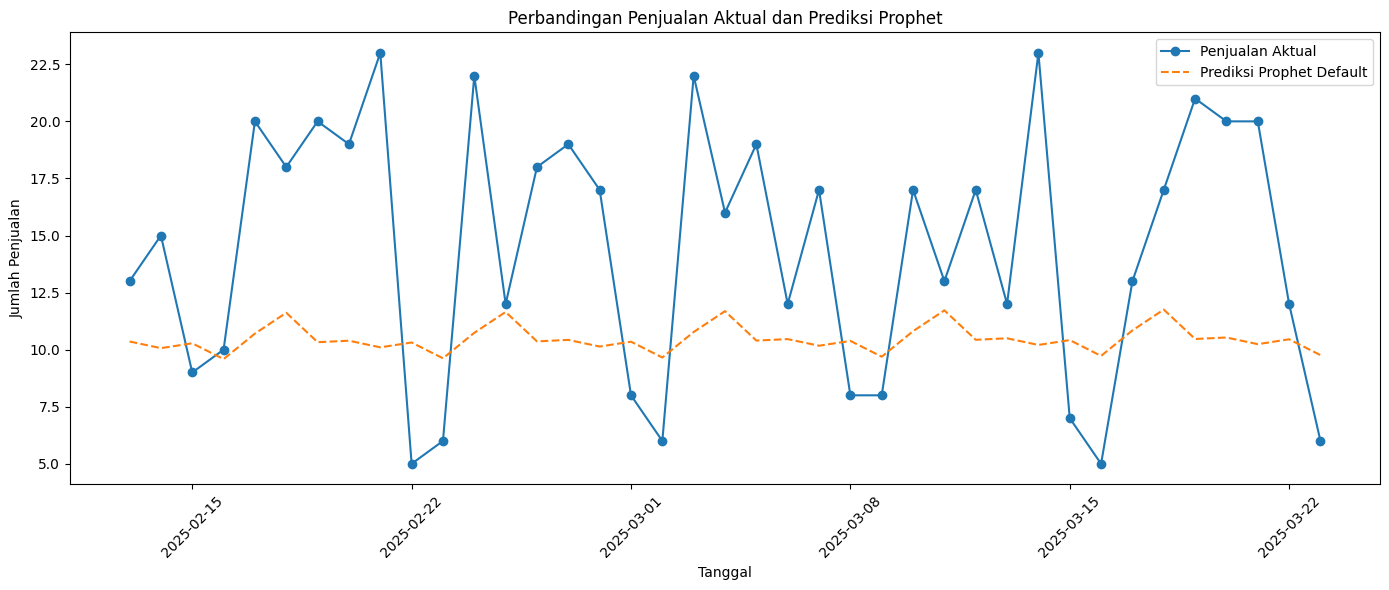

In [448]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    hasil_prediksi['ds'],
    hasil_prediksi['y'],
    label='Penjualan Aktual',
    marker='o'
)

plt.plot(
    hasil_prediksi['ds'],
    hasil_prediksi['y_prediksi'],
    label='Prediksi Prophet Default',
    linestyle='--'
)

plt.title('Perbandingan Penjualan Aktual dan Prediksi Prophet')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Penjualan')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Prediksi 1 hari berikutnya

In [449]:
model_final = Prophet()
model_final.fit(data_prophet)

tanggal_berikutnya = pd.DataFrame({
    'ds': [data_prophet['ds'].max() + pd.Timedelta(days=1)]
})

forecast_berikutnya = model_final.predict(tanggal_berikutnya)

print("Tanggal prediksi:",
      forecast_berikutnya['ds'].iloc[0].date())

print("Prediksi jumlah penjualan:",
      max(0, round(forecast_berikutnya['yhat'].iloc[0])))

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Tanggal prediksi: 2025-03-24
Prediksi jumlah penjualan: 14


Pengujian Konfigurasi

In [450]:
import pandas as pd
import numpy as np
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

konfigurasi = [
    {'changepoint_prior_scale': 0.001,
     'seasonality_prior_scale': 1.0,
     'seasonality_mode': 'additive'},

    {'changepoint_prior_scale': 0.01,
     'seasonality_prior_scale': 1.0,
     'seasonality_mode': 'additive'},

    {'changepoint_prior_scale': 0.05,
     'seasonality_prior_scale': 1.0,
     'seasonality_mode': 'additive'},

    {'changepoint_prior_scale': 0.1,
     'seasonality_prior_scale': 1.0,
     'seasonality_mode': 'additive'},

    {'changepoint_prior_scale': 0.05,
     'seasonality_prior_scale': 0.1,
     'seasonality_mode': 'additive'},

    {'changepoint_prior_scale': 0.05,
     'seasonality_prior_scale': 1.0,
     'seasonality_mode': 'multiplicative'}
]

hasil_evaluasi = []

aktual = test['y'].to_numpy()
mask = aktual != 0

for i, params in enumerate(konfigurasi, start=1):
    model = Prophet(**params)
    model.fit(train)

    prediksi = model.predict(test[['ds']])['yhat'].to_numpy()

    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))

    mape = (
        np.mean(np.abs(
            (aktual[mask] - prediksi[mask]) / aktual[mask]
        )) * 100
        if mask.sum() > 0 else np.nan
    )

    hasil_evaluasi.append({
        'Percobaan': i,
        **params,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

hasil_tuning = pd.DataFrame(hasil_evaluasi)

display(
    hasil_tuning.sort_values('MAPE').reset_index(drop=True)
)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
ERROR:cmdstanpy:Chain [1] error: code '1' Operation not permitted
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling d

,Percobaan,changepoint_prior_scale,seasonality_prior_scale,seasonality_mode,MAE,RMSE,MAPE
0,6,0.050,1.0,multiplicative,5.541946,6.614373,38.327820
1,2,0.010,1.0,additive,5.299460,6.262180,39.135796
2,1,0.001,1.0,additive,5.350859,6.325650,39.182845
3,3,0.050,1.0,additive,5.664633,6.713855,39.354530
4,5,0.050,0.1,additive,5.638361,6.679462,39.354702
5,4,0.100,1.0,additive,6.262365,7.515290,40.045180


Menguji nilai seasonality_prior_scale

In [451]:
nilai_seasonality = [0.01, 0.05, 0.1, 0.2, 0.5]

hasil_lanjutan = []

for nilai in nilai_seasonality:
    model = Prophet(
        changepoint_prior_scale=0.05,
        seasonality_prior_scale=nilai,
        seasonality_mode='additive'
    )

    model.fit(train)

    prediksi = model.predict(test[['ds']])['yhat'].to_numpy()
    aktual = test['y'].to_numpy()

    mask = aktual != 0

    mape = (
        np.mean(
            np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])
        ) * 100
        if mask.sum() > 0 else np.nan
    )

    hasil_lanjutan.append({
        'seasonality_prior_scale': nilai,
        'MAPE': mape,
        'MAE': mean_absolute_error(aktual, prediksi),
        'RMSE': np.sqrt(mean_squared_error(aktual, prediksi))
    })

display(
    pd.DataFrame(hasil_lanjutan).sort_values('MAPE')
)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to overr

,seasonality_prior_scale,MAPE,MAE,RMSE
2,0.10,39.354702,5.638361,6.679462
3,0.20,39.364980,5.664352,6.712850
4,0.50,39.396305,5.698496,6.755626
1,0.05,39.488263,5.641415,6.673224
0,0.01,41.183859,5.953015,6.969113


Tuning terbaru (ini sempat diganti)

In [452]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

nilai_seasonality = [0.5, 0.75, 1.0, 1.25, 1.5]

hasil_lanjutan = []

aktual = test['y'].to_numpy()
mask = aktual != 0

for nilai in nilai_seasonality:
    model = Prophet(
        changepoint_prior_scale=0.05,
        seasonality_prior_scale=nilai,
        seasonality_mode='multiplicative'
    )

    model.fit(train)
    prediksi = model.predict(test[['ds']])['yhat'].to_numpy()

    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))

    mape = (
        np.mean(
            np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])
        ) * 100
        if mask.sum() > 0 else np.nan
    )

    hasil_lanjutan.append({
        'changepoint_prior_scale': 0.05,
        'seasonality_prior_scale': nilai,
        'seasonality_mode': 'multiplicative',
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

hasil_lanjutan = pd.DataFrame(hasil_lanjutan)

display(
    hasil_lanjutan
    .sort_values('MAPE')
    .reset_index(drop=True)
    .round(4)
)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to overr

,changepoint_prior_scale,seasonality_prior_scale,seasonality_mode,MAE,RMSE,MAPE
0,0.05,0.50,multiplicative,5.5500,6.6316,38.2312
1,0.05,0.75,multiplicative,5.5341,6.6054,38.2975
2,0.05,1.00,multiplicative,5.5419,6.6144,38.3278
3,0.05,1.25,multiplicative,5.5289,6.5949,38.3538
4,0.05,1.50,multiplicative,5.5297,6.5935,38.3946


Coba dengan ChangePoint terbaru (ini juga diubah)

In [453]:
nilai_changepoint = [0.01, 0.025, 0.05, 0.075, 0.1, 0.2, 0.3]

hasil_changepoint = []

aktual = test['y'].to_numpy()
mask = aktual != 0

for nilai in nilai_changepoint:
    model = Prophet(
        changepoint_prior_scale=nilai,
        seasonality_prior_scale=0.50,
        seasonality_mode='multiplicative'
    )

    model.fit(train)

    prediksi = model.predict(test[['ds']])['yhat'].to_numpy()

    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))

    mape = (
        np.mean(
            np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])
        ) * 100
        if mask.sum() > 0 else np.nan
    )

    hasil_changepoint.append({
        'changepoint_prior_scale': nilai,
        'seasonality_prior_scale': 0.50,
        'seasonality_mode': 'multiplicative',
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

hasil_changepoint = pd.DataFrame(hasil_changepoint)

display(
    hasil_changepoint
    .sort_values('MAPE')
    .reset_index(drop=True)
    .round(4)
)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to overr

,changepoint_prior_scale,seasonality_prior_scale,seasonality_mode,MAE,RMSE,MAPE
0,0.025,0.5,multiplicative,5.1479,6.1084,38.2276
1,0.050,0.5,multiplicative,5.5500,6.6316,38.2312
2,0.300,0.5,multiplicative,6.0508,7.2536,39.4562
3,0.075,0.5,multiplicative,6.1308,7.3504,39.6217
4,0.100,0.5,multiplicative,6.3004,7.5948,39.8325
5,0.010,0.5,multiplicative,5.3765,6.2827,40.4162
6,0.200,0.5,multiplicative,6.6164,7.9985,40.7954


In [454]:
print(
    hasil_changepoint
    .sort_values('MAPE')
    .to_string(index=False)
)

 changepoint_prior_scale  seasonality_prior_scale seasonality_mode      MAE     RMSE      MAPE
                   0.025                      0.5   multiplicative 5.147921 6.108436 38.227621
                   0.050                      0.5   multiplicative 5.549967 6.631568 38.231167
                   0.300                      0.5   multiplicative 6.050823 7.253607 39.456205
                   0.075                      0.5   multiplicative 6.130801 7.350398 39.621742
                   0.100                      0.5   multiplicative 6.300407 7.594795 39.832539
                   0.010                      0.5   multiplicative 5.376487 6.282692 40.416239
                   0.200                      0.5   multiplicative 6.616369 7.998523 40.795369


Prediksi Finall?

In [455]:
from prophet import Prophet

# Melatih ulang Prophet menggunakan seluruh data historis
model_final = Prophet()
model_final.fit(data_prophet)

# Membuat prediksi untuk 1 hari ke depan
future = model_final.make_future_dataframe(
    periods=1,
    freq='D'
)

# Menghasilkan prediksi
forecast_final = model_final.predict(future)

# Mengambil hasil prediksi untuk tanggal berikutnya
hasil_prediksi_final = forecast_final[
    forecast_final['ds'] > data_prophet['ds'].max()
][['ds', 'yhat', 'yhat_lower', 'yhat_upper']]

print("Prediksi Kuantitas Penjualan 1 Hari ke Depan:")
print(hasil_prediksi_final.to_string(index=False))

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Prediksi Kuantitas Penjualan 1 Hari ke Depan:
        ds      yhat  yhat_lower  yhat_upper
2025-03-24 13.537513     7.70622   19.486768


(perbandingan)

In [456]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Fungsi evaluasi model
def evaluasi_prophet(model, train, test, nama_model):
    model.fit(train)

    forecast = model.predict(test[['ds']])

    aktual = test['y'].to_numpy()
    prediksi = forecast['yhat'].to_numpy()

    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))

    mask = aktual != 0
    mape = (
        np.mean(np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])) * 100
        if mask.sum() > 0 else np.nan
    )

    return {
        'Model': nama_model,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    }

# 1. Prophet default
model_default = Prophet()

hasil_default = evaluasi_prophet(
    model_default, train, test, 'Prophet Default'
)

# 2. Prophet dengan parameter terbaik hasil tuning manual
model_tuning = Prophet(
    changepoint_prior_scale=0.025,
    seasonality_prior_scale=0.5,
    seasonality_mode='multiplicative'
)

hasil_tuning = evaluasi_prophet(
    model_tuning, train, test, 'Prophet Tuning Manual'
)

# Menampilkan perbandingan
hasil_perbandingan = pd.DataFrame([
    hasil_default,
    hasil_tuning
])

print(hasil_perbandingan.to_string(index=False))

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


                Model      MAE     RMSE      MAPE
      Prophet Default 5.674008 6.725848 39.361723
Prophet Tuning Manual 5.147921 6.108436 38.227621


(prediksi model terbaik)

In [457]:
from prophet import Prophet
import pandas as pd

# Melatih model terbaik menggunakan seluruh data historis
model_final = Prophet(
    changepoint_prior_scale=0.025,
    seasonality_prior_scale=0.5,
    seasonality_mode='multiplicative'
)

model_final.fit(data_prophet)

# Membuat prediksi untuk satu hari berikutnya
future = model_final.make_future_dataframe(
    periods=1,
    freq='D'
)

forecast_final = model_final.predict(future)

# Mengambil prediksi untuk tanggal setelah data terakhir
hasil_prediksi_final = forecast_final[
    forecast_final['ds'] > data_prophet['ds'].max()
][['ds', 'yhat', 'yhat_lower', 'yhat_upper']].copy()

# Kuantitas penjualan berupa bilangan bulat dan tidak negatif
hasil_prediksi_final['yhat'] = (
    hasil_prediksi_final['yhat'].clip(lower=0).round().astype(int)
)

print("Prediksi Kuantitas Penjualan untuk 1 Hari ke Depan:")
print(hasil_prediksi_final.to_string(index=False))

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Prediksi Kuantitas Penjualan untuk 1 Hari ke Depan:
        ds  yhat  yhat_lower  yhat_upper
2025-03-24    14    7.560364    20.10281


(ini gatau apa)

In [458]:
print("Jumlah data latih:", len(train))
print("Jumlah data uji:", len(test))
print("Periode latih:", train['ds'].min(), "sampai", train['ds'].max())
print("Periode uji:", test['ds'].min(), "sampai", test['ds'].max())

Jumlah data latih: 342
Jumlah data uji: 39
Periode latih: 2024-03-01 00:00:00 sampai 2025-02-12 00:00:00
Periode uji: 2025-02-13 00:00:00 sampai 2025-03-23 00:00:00


In [459]:
konfigurasi_perbandingan = [
    {
        'changepoint_prior_scale': 0.01,
        'seasonality_prior_scale': 0.20,
        'seasonality_mode': 'additive'
    },
    {
        'changepoint_prior_scale': 0.05,
        'seasonality_prior_scale': 0.50,
        'seasonality_mode': 'multiplicative'
    }
]

hasil_perbandingan = []

aktual = test['y'].to_numpy()
mask = aktual != 0

for params in konfigurasi_perbandingan:
    model = Prophet(**params)
    model.fit(train)

    prediksi = model.predict(test[['ds']])['yhat'].to_numpy()

    hasil_perbandingan.append({
        **params,
        'MAE': mean_absolute_error(aktual, prediksi),
        'RMSE': np.sqrt(mean_squared_error(aktual, prediksi)),
        'MAPE': (
            np.mean(
                np.abs(
                    (aktual[mask] - prediksi[mask]) / aktual[mask]
                )
            ) * 100
            if mask.sum() > 0 else np.nan
        )
    })

display(
    pd.DataFrame(hasil_perbandingan)
    .sort_values('MAPE')
    .reset_index(drop=True)
    .round(4)
)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,changepoint_prior_scale,seasonality_prior_scale,seasonality_mode,MAE,RMSE,MAPE
0,0.05,0.5,multiplicative,5.5500,6.6316,38.2312
1,0.01,0.2,additive,5.2772,6.2321,39.1766


**Pemeriksaan Data**

Pemeriksaan pola data pada hari dalam seminggu

In [460]:
# Pastikan kolom tanggal bertipe datetime
data_prophet['ds'] = pd.to_datetime(data_prophet['ds'])

# Menambahkan informasi hari
data_prophet['Hari'] = data_prophet['ds'].dt.day_name()

# Urutan hari agar grafik dan tabel lebih mudah dibaca
urutan_hari = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

ringkasan_hari = (
    data_prophet.groupby('Hari')['y']
    .agg(['mean', 'median', 'std', 'count'])
    .reindex(urutan_hari)
    .round(2)
)

display(ringkasan_hari)

,mean,median,std,count
Hari,,,,
Monday,9.89,9.0,5.86,55
Tuesday,10.40,10.0,5.40,55
Wednesday,9.62,9.0,5.62,52
Thursday,9.44,9.0,4.71,54
Friday,9.50,8.0,5.60,56
Saturday,8.55,8.0,4.17,55
Sunday,7.76,6.5,4.79,54


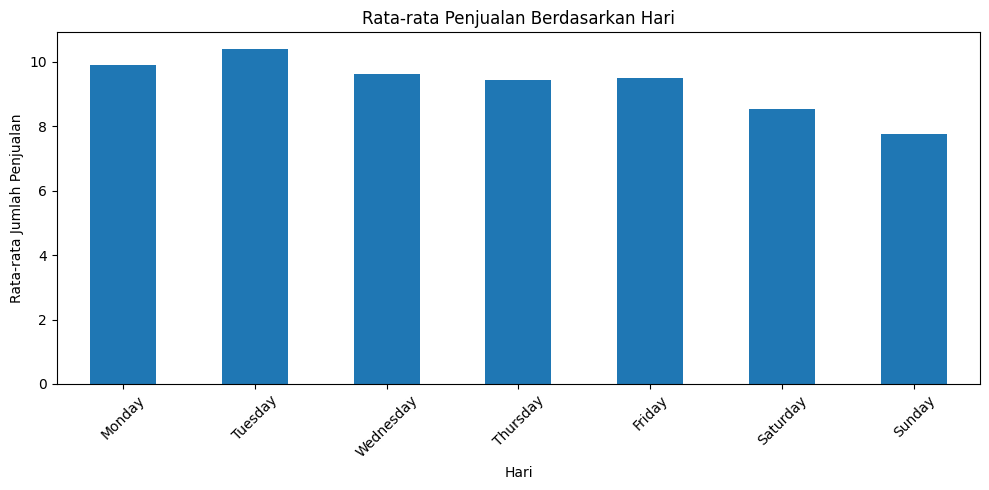

In [461]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
ringkasan_hari['mean'].plot(kind='bar')

plt.title('Rata-rata Penjualan Berdasarkan Hari')
plt.xlabel('Hari')
plt.ylabel('Rata-rata Jumlah Penjualan')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Baseline sederhana

In [462]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Urutkan data berdasarkan tanggal
data_baseline = (
    data_prophet[['ds', 'y']]
    .sort_values('ds')
    .reset_index(drop=True)
)

# Pembagian data yang sama: 80% latih, 20% uji
batas = int(len(data_baseline) * 0.8)

train = data_baseline.iloc[:batas].copy()
test = data_baseline.iloc[batas:].copy()

# Prediksi menggunakan penjualan pada pengamatan sebelumnya
data_baseline['prediksi_naive'] = data_baseline['y'].shift(1)

hasil_baseline = data_baseline.iloc[batas:].copy()

aktual = hasil_baseline['y'].to_numpy()
prediksi = hasil_baseline['prediksi_naive'].to_numpy()

# Baris pertama data uji memiliki prediksi dari pengamatan sebelumnya
valid = ~np.isnan(prediksi)
aktual = aktual[valid]
prediksi = prediksi[valid]

mae_naive = mean_absolute_error(aktual, prediksi)
rmse_naive = np.sqrt(mean_squared_error(aktual, prediksi))

mask = aktual != 0
mape_naive = (
    np.mean(np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])) * 100
    if mask.sum() > 0 else np.nan
)

print(f"MAE baseline  : {mae_naive:.3f}")
print(f"RMSE baseline : {rmse_naive:.3f}")
print(f"MAPE baseline : {mape_naive:.2f}%")

MAE baseline  : 5.364
RMSE baseline : 7.013
MAPE baseline : 57.28%


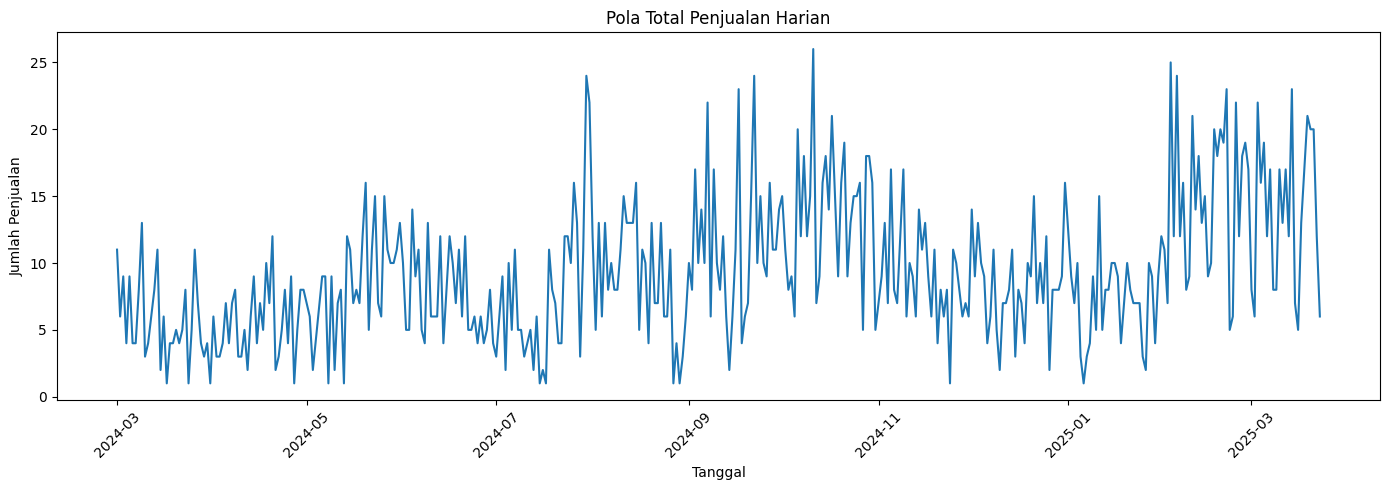

In [463]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(data_prophet['ds'], data_prophet['y'])
plt.title('Pola Total Penjualan Harian')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Penjualan')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Prediksi dengan hasil tuning (final)**

In [464]:
from prophet import Prophet

model_tuning = Prophet(
    changepoint_prior_scale=0.10,
    seasonality_prior_scale=0.20,
    seasonality_mode='additive'
)

model_tuning.fit(train)

print("Model Prophet hasil tuning berhasil dilatih.")

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Model Prophet hasil tuning berhasil dilatih.


In [465]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

forecast_test = model_tuning.predict(test[['ds']])

aktual = test['y'].to_numpy()
prediksi = forecast_test['yhat'].to_numpy()

mae = mean_absolute_error(aktual, prediksi)
rmse = np.sqrt(mean_squared_error(aktual, prediksi))

mask = aktual != 0

mape = (
    np.mean(np.abs((aktual[mask] - prediksi[mask]) / aktual[mask])) * 100
    if mask.sum() > 0 else np.nan
)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAPE : {mape:.2f}%")

MAE  : 6.2148
RMSE : 8.0911
MAPE : 59.72%


In [466]:
# Melatih ulang model menggunakan seluruh data
model_final = Prophet(
    changepoint_prior_scale=0.10,
    seasonality_prior_scale=0.20,
    seasonality_mode='additive'
)

model_final.fit(data_prophet)

# Membuat tanggal prediksi 7 hari ke depan
future = model_final.make_future_dataframe(
    periods=7,
    freq='D'
)

# Menghasilkan prediksi
forecast_final = model_final.predict(future)

# Mengambil hasil prediksi 7 hari ke depan
tanggal_terakhir = data_prophet['ds'].max()

hasil_prediksi = forecast_final[
    forecast_final['ds'] > tanggal_terakhir
][['ds', 'yhat', 'yhat_lower', 'yhat_upper']].copy()

# Kuantitas penjualan tidak boleh negatif
for kolom in ['yhat', 'yhat_lower', 'yhat_upper']:
    hasil_prediksi[kolom] = hasil_prediksi[kolom].clip(lower=0)

# Membulatkan prediksi karena penjualan berupa jumlah barang
hasil_prediksi['Prediksi Penjualan'] = (
    hasil_prediksi['yhat'].round().astype(int)
)

hasil_prediksi = hasil_prediksi.rename(columns={
    'ds': 'Tanggal',
    'yhat_lower': 'Batas Bawah',
    'yhat_upper': 'Batas Atas'
})

display(hasil_prediksi[
    ['Tanggal', 'Prediksi Penjualan', 'Batas Bawah', 'Batas Atas']
])

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


,Tanggal,Prediksi Penjualan,Batas Bawah,Batas Atas
381,2025-03-24,14,7.420007,19.937711
382,2025-03-25,14,8.368093,20.197134
383,2025-03-26,14,7.458432,19.804904
384,2025-03-27,14,7.576437,19.171630
385,2025-03-28,14,7.571771,19.627454
386,2025-03-29,13,6.371154,18.205283
387,2025-03-30,12,5.625217,17.646250


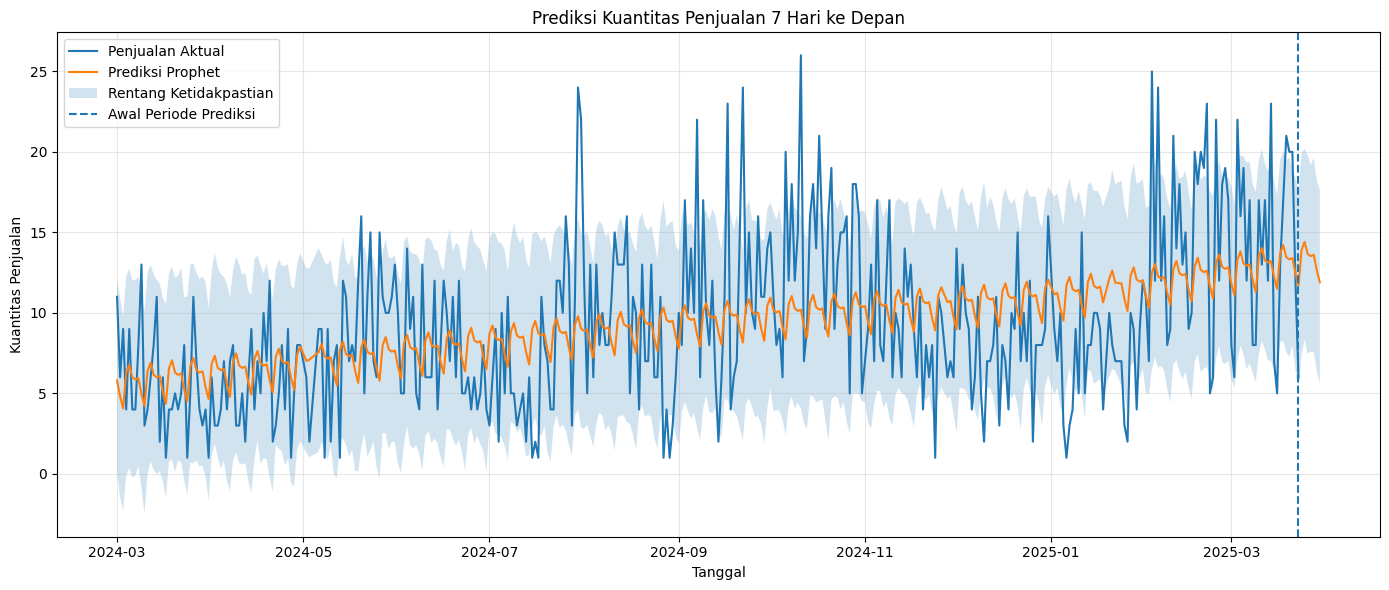

In [467]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    data_prophet['ds'],
    data_prophet['y'],
    label='Penjualan Aktual'
)

ax.plot(
    forecast_final['ds'],
    forecast_final['yhat'],
    label='Prediksi Prophet'
)

ax.fill_between(
    forecast_final['ds'],
    forecast_final['yhat_lower'],
    forecast_final['yhat_upper'],
    alpha=0.2,
    label='Rentang Ketidakpastian'
)

ax.axvline(
    tanggal_terakhir,
    linestyle='--',
    label='Awal Periode Prediksi'
)

ax.set_title('Prediksi Kuantitas Penjualan 7 Hari ke Depan')
ax.set_xlabel('Tanggal')
ax.set_ylabel('Kuantitas Penjualan')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

MENGATASI DATA

In [468]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Salinan data untuk eksperimen
df_ets = data_prophet[['ds', 'y']].copy()

df_ets['ds'] = pd.to_datetime(df_ets['ds'])
df_ets['y'] = pd.to_numeric(df_ets['y'], errors='coerce')

df_ets = (
    df_ets.dropna(subset=['ds', 'y'])
          .sort_values('ds')
          .drop_duplicates(subset='ds', keep='last')
          .reset_index(drop=True)
)

print("Jumlah observasi:", len(df_ets))
print("Tanggal awal:", df_ets['ds'].min())
print("Tanggal akhir:", df_ets['ds'].max())
print("Jumlah nilai penjualan nol:", (df_ets['y'] == 0).sum())
print("Jumlah nilai penjualan negatif:", (df_ets['y'] < 0).sum())

Jumlah observasi: 381
Tanggal awal: 2024-03-01 00:00:00
Tanggal akhir: 2025-03-23 00:00:00
Jumlah nilai penjualan nol: 0
Jumlah nilai penjualan negatif: 0


(data handling)

Jumlah tanggal yang tidak tercatat: 7

Daftar tanggal yang tidak tercatat:
['2024-05-01', '2024-05-04', '2024-05-05', '2024-11-27', '2025-01-01', '2025-01-19', '2025-01-23']


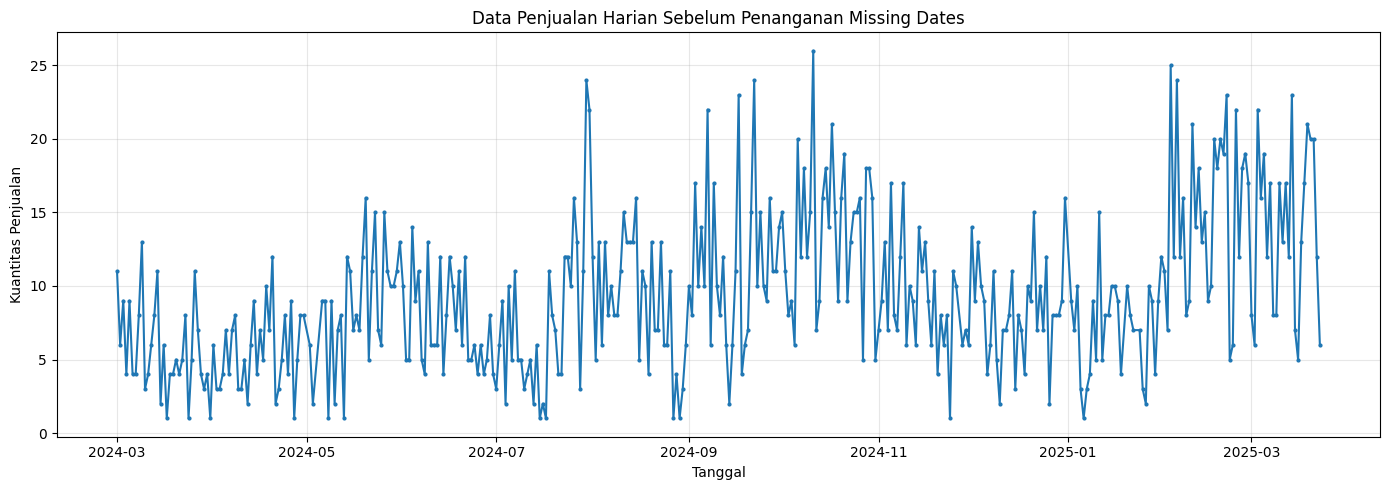

In [469]:
# Membuat kalender tanggal harian lengkap
kalender = pd.date_range(
    start=df_ets['ds'].min(),
    end=df_ets['ds'].max(),
    freq='D'
)

tanggal_tercatat = pd.DatetimeIndex(df_ets['ds'].unique())
tanggal_hilang = kalender.difference(tanggal_tercatat)

print("Jumlah tanggal yang tidak tercatat:", len(tanggal_hilang))
print("\nDaftar tanggal yang tidak tercatat:")
print(tanggal_hilang.strftime('%Y-%m-%d').to_list())

# Visualisasi kuantitas penjualan
plt.figure(figsize=(14, 5))
plt.plot(df_ets['ds'], df_ets['y'], marker='o', markersize=2)
plt.title('Data Penjualan Harian Sebelum Penanganan Missing Dates')
plt.xlabel('Tanggal')
plt.ylabel('Kuantitas Penjualan')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [470]:
# Gunakan hanya jika tanggal yang hilang memang berarti tidak ada penjualan
df_missing = (
    df_ets.set_index('ds')
          .reindex(kalender)
          .rename_axis('ds')
          .reset_index()
)

df_missing['y'] = df_missing['y'].fillna(0)

print(df_missing[df_missing['ds'].isin(tanggal_hilang)])

            ds    y
61  2024-05-01  0.0
64  2024-05-04  0.0
65  2024-05-05  0.0
271 2024-11-27  0.0
306 2025-01-01  0.0
324 2025-01-19  0.0
328 2025-01-23  0.0


Time-Series Data Augmentation

In [471]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Siapkan data kronologis
df_aug = df_ets.copy().sort_values('ds').reset_index(drop=True)

# Contoh fitur: 3 hari sebelumnya dan hari dalam minggu
for lag in [1, 2, 3]:
    df_aug[f'lag_{lag}'] = df_aug['y'].shift(lag)

df_aug['day_of_week'] = df_aug['ds'].dt.dayofweek

df_supervised = df_aug.dropna().reset_index(drop=True)

features = ['lag_1', 'lag_2', 'lag_3', 'day_of_week']
X = df_supervised[features].to_numpy(dtype=float)
y_target = df_supervised['y'].to_numpy(dtype=float)

# Split tetap kronologis: 90% awal untuk train, sisanya untuk test
batas = int(len(X) * 0.9)
X_train, X_test = X[:batas].copy(), X[batas:].copy()
y_train, y_test = y_target[:batas].copy(), y_target[batas:].copy()

# Baseline: tanpa augmentation
model_baseline = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
model_baseline.fit(X_train, y_train)
pred_baseline = model_baseline.predict(X_test)

# Augmentation sederhana: jittering hanya pada fitur lag
rng = np.random.default_rng(42)
X_aug = X_train.copy()

# Skala noise berdasarkan variasi data latih
std_lag = np.std(X_train[:, :3])
noise = rng.normal(
    loc=0,
    scale=0.03 * std_lag,
    size=(len(X_train), 3)
)

X_aug[:, :3] = np.maximum(0, X_aug[:, :3] + noise)

# Gabungkan data asli dan variasi sintetis
X_train_aug = np.vstack([X_train, X_aug])
y_train_aug = np.concatenate([y_train, y_train])

model_aug = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
model_aug.fit(X_train_aug, y_train_aug)
pred_aug = model_aug.predict(X_test)

def hitung_metrik(y_true, y_pred, nama):
    mask = y_true != 0
    return {
        'Model': nama,
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE (%)': (
            np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
            if mask.any() else np.nan
        )
    }

hasil_aug = pd.DataFrame([
    hitung_metrik(y_test, pred_baseline, 'QRT pembanding tanpa augmentation'),
    hitung_metrik(y_test, pred_aug, 'QRT pembanding dengan augmentation')
])

print(hasil_aug.to_string(index=False))

                             Model      MAE     RMSE  MAPE (%)
 QRT pembanding tanpa augmentation 4.760658 5.826769 37.555413
QRT pembanding dengan augmentation 4.666053 5.834331 35.485783


Anomaly Detection

Jumlah kandidat anomali: 6
        ds  y  rolling_median  skor_anomali
2024-06-21 12             6.0       4.04700
2024-08-23 13             7.0       4.04700
2024-10-27  5            16.0      -3.70975
2024-12-26  2             8.0      -4.04700
2024-12-31 16             9.0       4.72150
2025-01-11 15             8.0       4.72150


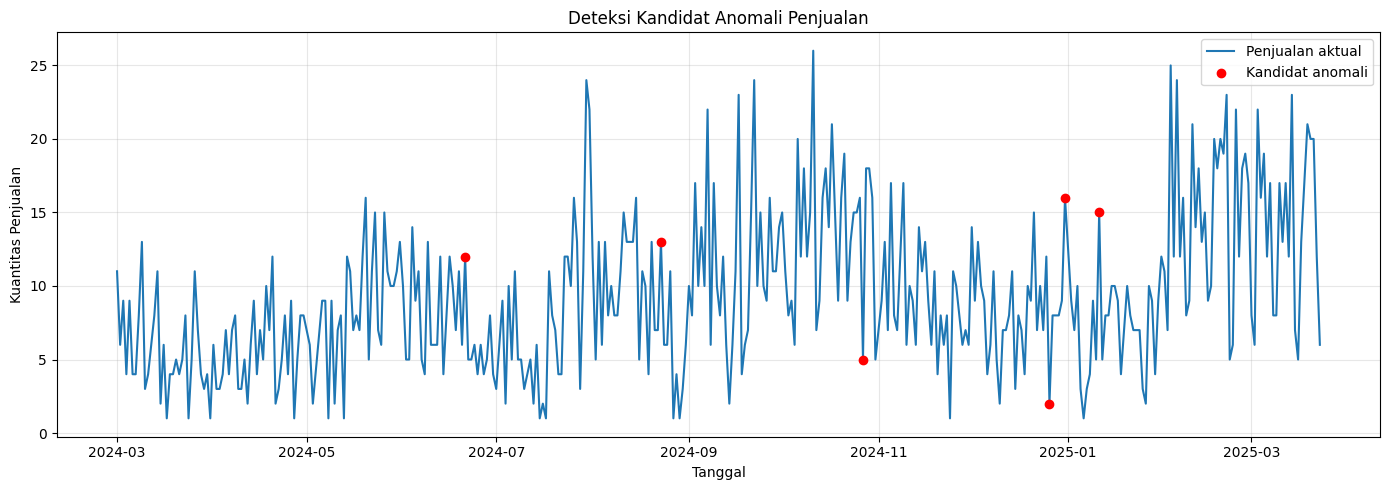

In [472]:
df_anomali = df_ets.copy().sort_values('ds').reset_index(drop=True)

# Median bergerak 7 hari, termasuk hari yang sedang diperiksa
df_anomali['rolling_median'] = (
    df_anomali['y']
    .rolling(window=7, center=True, min_periods=4)
    .median()
)

# Deviasi absolut dari median lokal
df_anomali['abs_deviasi'] = (
    df_anomali['y'] - df_anomali['rolling_median']
).abs()

# MAD lokal
df_anomali['MAD'] = (
    df_anomali['abs_deviasi']
    .rolling(window=7, center=True, min_periods=4)
    .median()
)

# Skor anomali robust
df_anomali['skor_anomali'] = (
    0.6745 * (df_anomali['y'] - df_anomali['rolling_median'])
    / df_anomali['MAD'].replace(0, np.nan)
)

# Ambang umum untuk penandaan kandidat anomali
df_anomali['anomali'] = df_anomali['skor_anomali'].abs() > 3.5

daftar_anomali = df_anomali[df_anomali['anomali']]

print("Jumlah kandidat anomali:", len(daftar_anomali))
print(
    daftar_anomali[
        ['ds', 'y', 'rolling_median', 'skor_anomali']
    ].to_string(index=False)
)

# Visualisasi
plt.figure(figsize=(14, 5))
plt.plot(df_anomali['ds'], df_anomali['y'], label='Penjualan aktual')
plt.scatter(
    daftar_anomali['ds'],
    daftar_anomali['y'],
    color='red',
    label='Kandidat anomali',
    zorder=3
)
plt.title('Deteksi Kandidat Anomali Penjualan')
plt.xlabel('Tanggal')
plt.ylabel('Kuantitas Penjualan')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Time-Series Cross-Validation

In [473]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

df_cv = df_ets[['ds', 'y']].copy().sort_values('ds').reset_index(drop=True)

# Konfigurasi model yang dibandingkan
konfigurasi = {
    'Prophet Default': {},
    'Prophet Tuning Manual': {
        'changepoint_prior_scale': 0.025,
        'seasonality_prior_scale': 0.5,
        'seasonality_mode': 'multiplicative'
    }
}

# Tiga titik evaluasi berurutan; setiap model hanya belajar dari masa lalu
n = len(df_cv)
ukuran_awal = int(n * 0.6)
ukuran_validasi = max(1, int(n * 0.1))

hasil_cv = []

for nama_model, params in konfigurasi.items():
    for fold in range(3):
        akhir_train = ukuran_awal + fold * ukuran_validasi
        akhir_test = min(akhir_train + ukuran_validasi, n)

        train_cv = df_cv.iloc[:akhir_train].copy()
        test_cv = df_cv.iloc[akhir_train:akhir_test].copy()

        if len(test_cv) == 0:
            continue

        model = Prophet(**params)
        model.fit(train_cv)

        pred = model.predict(test_cv[['ds']])['yhat'].to_numpy()
        aktual = test_cv['y'].to_numpy()

        mask = aktual != 0
        mape = (
            np.mean(np.abs((aktual[mask] - pred[mask]) / aktual[mask])) * 100
            if mask.any() else np.nan
        )

        hasil_cv.append({
            'Model': nama_model,
            'Fold': fold + 1,
            'Tanggal Awal Uji': test_cv['ds'].min(),
            'Tanggal Akhir Uji': test_cv['ds'].max(),
            'MAE': mean_absolute_error(aktual, pred),
            'RMSE': np.sqrt(mean_squared_error(aktual, pred)),
            'MAPE (%)': mape
        })

hasil_cv = pd.DataFrame(hasil_cv)

print("Hasil setiap fold:")
print(hasil_cv.to_string(index=False))

print("\nRata-rata metrik setiap model:")
print(
    hasil_cv.groupby('Model')[['MAE', 'RMSE', 'MAPE (%)']]
    .mean()
    .to_string()
)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to overr

Hasil setiap fold:
                Model  Fold Tanggal Awal Uji Tanggal Akhir Uji      MAE     RMSE   MAPE (%)
      Prophet Default     1       2024-10-18        2024-11-24 4.499130 5.146479  84.516981
      Prophet Default     2       2024-11-25        2025-01-03 4.759291 5.494150  95.492703
      Prophet Default     3       2025-01-04        2025-02-12 4.255529 5.675391  89.968940
Prophet Tuning Manual     1       2024-10-18        2024-11-24 4.448078 5.054163  82.737104
Prophet Tuning Manual     2       2024-11-25        2025-01-03 4.762244 5.604027  96.114311
Prophet Tuning Manual     3       2025-01-04        2025-02-12 4.756775 5.913368 103.451907

Rata-rata metrik setiap model:
                            MAE      RMSE   MAPE (%)
Model                                               
Prophet Default        4.504650  5.438673  89.992875
Prophet Tuning Manual  4.655699  5.523853  94.101107
